# Batch_03 EDA dossier

Section-by-section analysis of the batch_03 data. Each section states
what is measured and **which design decision it feeds**; a Findings
stub at the end of each section collects the conclusions that flow
back into the design's EDA-gated open questions.

Prerequisite read: `00_batch03_overview.ipynb` (sources, schemas,
entity diagram).

## 0. What this data cannot answer

- **No labels** — attribution/conversion data is not in batch_03; no
  CVR, class balance, or label-volume analysis here.
- **No user-level signal** — user/device identifiers are anonymized;
  user features cannot be assessed.
- **No loss side** — the firehose sample is wins-only by construction;
  nothing here describes lost or non-bid auctions.
- **No timing** — every stream timestamp (`rx_timestamp_usecs`,
  `auctionid.timestamp`) was randomized by the anonymization (values
  spread uniformly over 2002–2286). Ordering and delay analysis are
  impossible on the sample; timing comes from the impression-delay
  CSV (section 6).
- **No volume representativity** — 933 events; volumes come from the
  traffic CSVs (section 6), not from the sample.

In [386]:
import matplotlib.pyplot as plt
import pandas as pd
from itables import init_notebook_mode

from eda_tools import (
    TRAFFIC_DIR,
    load_activity,
    load_candidates,
    load_delivery_control,
    load_firehose,
)

pd.set_option("display.max_columns", 200)
# Databricks-like interactive tables (search/sort/paginate) for every DataFrame
init_notebook_mode(all_interactive=True, connected=False)

events = load_firehose()
candidates = load_candidates()
activity = load_activity()
entities = load_delivery_control()

# Shared derived column (stream timestamps are randomized by the
# anonymization — no datetime derivations are possible on this sample)
candidates["bid_micros"] = pd.to_numeric(candidates["bidding.bid_price_micros"])
print(events.shape, candidates.shape, activity.shape, entities.shape)

(933, 172) (4569, 20) (2660, 20) (130, 84)


## 1. Feature availability at bid time

**Feeds: the candidate feature list and the GBDT input schema**
(request-derived features are the model's main input; this section is
the reason we asked for samples).

- Coverage (non-null %) of every bid-time field: `app.bundle/name/
  publisher`, `device.devicetype/os`, `geo.country` (+ finer geo if
  present), `imp[].video` specs (duration, placement, mimes, skip),
  `imp[].bidfloor`, PMP/deal presence, `cur`, `tmax`,
  `inventory_source`.
- Cardinality + top-k frequencies per categorical; concentration (mass
  in the top 10 bundles / geos).
- Cross-file consistency: field presence per `source_file`,
  `data_center` values, timestamp range per file (regions? days?).

Output: one coverage/cardinality table ranked for feature candidacy.

In [387]:
# Profile every field available at bid time.
#
# Fields come from two places: the scalar request.bidrequest.* columns, and
# the first imp[] entry (the ad slot and its video specs), flattened as imp0.*.
# Nested fields (lists/dicts such as imp0.video.mimes or imp0.pmp.deals) cannot
# be counted or grouped, so they get coverage (present-or-not) only; scalar
# fields get the full profile.

def is_nested(column: pd.Series) -> bool:
    return column.map(lambda v: isinstance(v, (list, dict))).any()

request_cols = [c for c in events.columns if c.startswith("request.bidrequest.")]
imp0 = pd.json_normalize(events["request.bidrequest.imp"].str[0]).add_prefix("imp0.")

bid_time_fields = pd.concat(
    [events[request_cols + ["request.inventory_source"]].reset_index(drop=True), imp0],
    axis=1,
)

nested_cols = [c for c in bid_time_fields.columns if is_nested(bid_time_fields[c])]
scalars = bid_time_fields.drop(columns=nested_cols)

nested_coverage = (
    bid_time_fields[nested_cols].notna().mean().round(3).rename("coverage").to_frame()
)

inventory = pd.DataFrame({
    "coverage": scalars.notna().mean().round(3),   # share of events carrying a value
    "nunique": scalars.nunique(),                  # distinct values across events
    "top_share": scalars.apply(                    # share held by the most common value
        lambda col: col.value_counts(normalize=True).max()
    ).round(3),
    "top10_share": scalars.apply(                  # share held by the 10 most common values
        lambda col: col.value_counts(normalize=True).head(10).sum()
    ).round(3),
    # every non-null value unique -> anonymized to random tokens; only
    # presence is assessable from this sample, not the distribution
    "anonymized": scalars.nunique() == scalars.notna().sum(),
})

print(f"{len(inventory)} scalar fields profiled; {len(nested_cols)} nested fields (coverage only)")

140 scalar fields profiled; 24 nested fields (coverage only)


In [388]:
from pprint import pprint

pprint(list(bid_time_fields.columns))

['request.bidrequest.id',
 'request.bidrequest.imp',
 'request.bidrequest.app.id',
 'request.bidrequest.app.name',
 'request.bidrequest.app.bundle',
 'request.bidrequest.app.publisher.id',
 'request.bidrequest.app.publisher.name',
 'request.bidrequest.app.content.livestream',
 'request.bidrequest.app.content.prodq',
 'request.bidrequest.app.storeurl',
 'request.bidrequest.device.ua',
 'request.bidrequest.device.ip',
 'request.bidrequest.device.geo.country',
 'request.bidrequest.device.geo.zip',
 'request.bidrequest.device.make',
 'request.bidrequest.device.os',
 'request.bidrequest.device.devicetype',
 'request.bidrequest.device.lmt',
 'request.bidrequest.device.ifa',
 'request.bidrequest.device.ext.augmented_device_screen_size',
 'request.bidrequest.device.ext.augmented_browser',
 'request.bidrequest.device.ext.augmented_browser_version',
 'request.bidrequest.device.ext.augmented_os',
 'request.bidrequest.device.ext.augmented_osv',
 'request.bidrequest.device.ext.augmented_model',
 'r

`nested_coverage` — list/dict-valued fields (e.g. `imp0.video.mimes`, `imp0.pmp.deals`) cannot be profiled like scalars; **coverage** is the share of events where the field is present at all.

In [389]:
# Nested bid-time fields (lists/dicts) — how often they are present
nested_coverage

coverage
request.bidrequest.imp                                 1.000
request.bidrequest.device.ext.augmented_models         0.998
request.bidrequest.user.geo.ext.regions                1.000
request.bidrequest.user.data                           0.947
request.bidrequest.user.eids                           0.718
request.bidrequest.user.ext.cross_device_mappin...     0.908
request.bidrequest.user.ext.cross_device_mappin...     0.908
request.bidrequest.user.ext.luids                      0.814
request.bidrequest.user.ext.unified_user_ids           1.000
request.bidrequest.user.ext.bgids                      0.792
request.bidrequest.cur                                 1.000
request.bidrequest.regs.gpp_sid                        0.347
request.bidrequest.source.schain.nodes                 1.000
request.bidrequest.ext.targeting_geo.regions           1.000
request.bidrequest.regs.ext.mspa_applied_sids          0.123
request.bidrequest.app.content.cat                     0.215
request.bidrequest.site.cat                            0.002
request.bidrequest.site.content.cat                    0.002
imp0.video.mimes                                       1.000
imp0.video.protocols                                   1.000
imp0.video.battr                                       1.000
imp0.video.playbackmethod                              1.000
imp0.pmp.deals                                         1.000
imp0.video.api                                         0.075

Columns of `inventory` (one row per scalar bid-time field):

- **coverage** — share of events carrying a value (nulls excluded from everything below).
- **nunique** — distinct values across events.
- **top_share** — share held by the single most common value; ≈1.0 means the field is effectively constant (no signal).
- **top10_share** — share covered by the 10 most common values; high = concentrated, low = spread out.
- **anonymized** — every non-null value is unique (random tokens): only presence is assessable from this sample, not the distribution.

In [390]:
# Scalar bid-time field inventory — searchable/sortable
inventory.sort_values(["coverage", "nunique"], ascending=[False, False]).reset_index(names="field")

field  coverage  nunique  \
0                                request.bidrequest.id     1.000      933   
1                request.bidrequest.device.geo.country     1.000      933   
2                         request.bidrequest.device.os     1.000      933   
3                 request.bidrequest.device.devicetype     1.000      933   
4    request.bidrequest.device.ext.augmented_device...     1.000      933   
..                                                 ...       ...      ...   
135           request.bidrequest.device.ext.ifv_hashed     0.002        2   
136                    request.bidrequest.user.ext.ifv     0.002        2   
137                 request.bidrequest.site.content.id     0.002        2   
138              request.bidrequest.site.content.title     0.002        2   
139                         request.bidrequest.app.ver     0.002        1   

     top_share  top10_share  anonymized  
0        0.001        0.011        True  
1        0.001        0.011        True  
2        0.001        0.011        True  
3        0.001        0.011        True  
4        0.001        0.011        True  
..         ...          ...         ...  
135      0.500        1.000        True  
136      0.500        1.000        True  
137      0.500        1.000        True  
138      0.500        1.000        True  
139      1.000        1.000       False  

[140 rows x 6 columns]

Columns of `files`:

- **events** — rows (= delivered impressions) in the file.
- **data_centers** — distinct `impression.data_center` values seen; tells whether the files slice by region.

In [391]:
# Are the three firehose files comparable slices of the same traffic?
#
# Timestamps cannot answer this: the anonymization randomized every stream
# timestamp (values spread uniformly over 2002-2286 instead of clustering in
# October 2026). What remains comparable: event counts and data centers.

def distinct_values(column: pd.Series) -> str:
    return ", ".join(sorted(column.dropna().unique()))

files = events.groupby("source_file").agg(
    events=("auction_key", "size"),
    data_centers=("impression.data_center", distinct_values),
)
files

events          data_centers
source_file                                         
firehose-full-1.ndjson     304  US_EAST_1, US_WEST_2
firehose-full-2.ndjson     319  US_EAST_1, US_WEST_2
firehose-full-3.ndjson     310  US_EAST_1, US_WEST_2

**Findings (1) — feature availability at bid time**

**Shape.** 933 events (304/319/310 per file, one data center each), 4,569
candidates, 2,660 activity events, 130 entities. The bid request exposes
**140 scalar + 24 nested fields**; 65 scalar fields have ≥99% coverage.

**Anonymization cuts deeper than the flag.** 51 full-coverage fields are
all-unique random tokens (`devicetype`, `os`, every geo level below
nothing — `country`, `city`, `zip`, `metro` —, `ua`, `ifa`, `make`,
`us_privacy`, user ids, trackers). Caution: fields with nunique *close
to* the non-null count (`augmented_make` 907/933, `user.geo.zip`
913/920, metros ~580 distinct) are randomized too — token collisions
keep them under the strict all-unique flag. Rule of thumb: **nunique ≈
non-null count ⇒ treat as anonymized.** Net effect: the device, geo,
user, and privacy axes are presence-only in this sample.

**The usable feature core** (high coverage, real variation, not anonymized):

- *App/content identity*: `app.bundle` (61 values, 95%), `app.id` (73,
  97%), `publisher.id/name` (18, 97%), `storeurl`, `app.name`.
- *Content metadata*: `content.genre` (115 values, 82%),
  `contentrating` (26, 84%), `content.len` (71%), `livestream` (97%),
  `network.name` (38%), `channel.name` (27%).
- *Video specs*: `maxduration` (39 values, 15–300 s, median 105),
  `minduration`, `w`/`h`, `mimes`/`protocols`/`playbackmethod` (100%
  as lists), `min/maxbitrate` (~32%).
- *Auction context*: `at` (auction type), `seller_id` (18),
  `inventory_source_rel` (5), `pmp.private_auction`, `pmp.deals`
  (100%), `bidfloor` (41% coverage, USD 5–16, `bidfloorcur` always USD),
  `ext.processing_time_ms`.

**Constants — exclude from any feature list** (~25 fields at
top_share ≥ 0.95): `video.placement`/`plcmt`/`linearity`,
`startdelay`, `lmt`, `test`, `schain.*`, `inventory_source`,
`environment_type`, `player_size`, `content.prodq`,
`content.language` (96% "en"), …

**Inventory is app/CTV, not web**: every `site.*` field is ≤2.6%
coverage — site features are ignorable for the MVP.

**User-side arrays** (`user.data` segments 95%, `eids` 72%,
`luids`/`bgids` ~80%) are present but ids are anonymized **and**
truncated to 3 entries — only presence is observable; their real
signal is unknowable until EDA runs client-side.

**One trap**: `tmax` (150–2,000 ms, median 1,075) is the upstream
exchange's timeout for the DSP, not the ad server's 10 ms budget for
the agent — don't read it as our latency envelope.

**Implication for the feature list**: the sample-evidenced candidates
are app/content identity + content metadata + video specs + auction
context. Device and geo features stay on the list on domain priors
only ("available, signal unverifiable here") — exactly the cut the
EDA-on-real-data phase must close.

## 2. Join & identity dossier

**Feeds: label-join readiness** (the join the whole label build
stands on) and the identity-triplet requirement.

- Key integrity: `auction_key` uniqueness; `requestid_str` uniqueness;
  duplicate events across the three files.
- Standing check: winner-in-candidates (933/933 at ingest).
- Id spaces: DSP integer ids (candidates/impressions) vs `ua_*` UUIDs
  (delivery control); bridge coverage (14 adsets / 121 line items) —
  what share of impression and candidate rows the export can enrich.
- Timestamp sanity: `rx_timestamp_usecs` ranges; impression-before-
  activity ordering violations.

`key_checks` — one row per join-key health check: **result** is what the sample shows, **expected** is what a healthy sample must show, **interpretation** says what passing means for the label build. Any result ≠ expected disqualifies the key as a join key as-is.

In [392]:
# Can the label build rely on these keys? One row per check:
# "expected" is what a healthy sample shows; any deviation means the key
# cannot serve as a join key as-is.

winners = events[["auction_key", "impression.adgroupid.lineitemid"]].rename(
    columns={"impression.adgroupid.lineitemid": "won_line_item_id"}
)
candidates_with_winner = candidates.merge(winners, on="auction_key")
auctions_won_by_a_listed_candidate = candidates_with_winner.loc[
    candidates_with_winner["line_item_id"] == candidates_with_winner["won_line_item_id"],
    "auction_key",
].nunique()

key_checks = pd.DataFrame([
    {
        "check": "auction_key unique per event",
        "result": f"{events['auction_key'].duplicated().sum()} duplicates",
        "expected": "0 duplicates",
        "interpretation": "one auction = one event; safe key joining events, candidates and activity",
    },
    {
        "check": "requestid_str unique per impression",
        "result": f"{events['impression.requestid_str'].duplicated().sum()} duplicates",
        "expected": "0 duplicates",
        "interpretation": "alternative impression-to-activity join key",
    },
    {
        "check": "won line item listed among the auction's candidates",
        "result": f"{auctions_won_by_a_listed_candidate} of {len(events)} auctions",
        "expected": f"{len(events)} of {len(events)}",
        "interpretation": "candidate arrays are complete: the delivered ad is always one of the listed candidates",
    },
])
key_checks

check               result  \
0                       auction_key unique per event         0 duplicates   
1                requestid_str unique per impression         0 duplicates   
2  won line item listed among the auction's candi...  933 of 933 auctions   

       expected                                     interpretation  
0  0 duplicates  one auction = one event; safe key joining even...  
1  0 duplicates        alternative impression-to-activity join key  
2    933 of 933  candidate arrays are complete: the delivered a...

Columns of `bridge_checks`:

- **stream side** — which stream rows are being matched (impressions or candidates) and on which DSP id.
- **export side** — the delivery-control column holding the same DSP id.
- **rows enrichable** — share of stream *rows* (traffic-weighted, not distinct ids) whose DSP id resolves to an exported entity, i.e. where the stream→config join lands and the row can be enriched with the client-side config (budgets, bid, targeting, hierarchy). Below 100% is expected here: the export is a matched 14-ad-set subset. In production, with the full feed, the same join should approach 100% — a shortfall there would be a data-quality finding.

In [393]:
# How much of the stream can the delivery-control export enrich?
#
# The export is a matched subset (14 ad sets), not the full catalog, so
# coverage below 100% is expected. The number that matters: the share of
# stream rows whose DSP id resolves to an exported entity — that is the
# share of rows we could enrich with client-side config (budgets, bid,
# targeting) in this sample. In production the delivery-control feed
# covers every ad set, so these shares measure the sample pairing only.
#
# Timestamp-ordering checks are impossible here: stream timestamps are
# randomized by the anonymization (section 0).

adsets = entities[entities["entity_type"] == "adset"]
ad_accounts = entities[entities["entity_type"] == "ad_account"]

def bridge_coverage(stream_ids: pd.Series, export_ids: pd.Series) -> str:
    exported = set(export_ids.dropna().astype(str))
    return f"{stream_ids.astype(str).isin(exported).mean():.0%}"

bridge_checks = pd.DataFrame([
    {
        "stream side": "impressions (won line item)",
        "export side": "adset.beeswax_line_item_id",
        "rows enrichable": bridge_coverage(
            events["impression.adgroupid.lineitemid"], adsets["beeswax_line_item_id"]
        ),
    },
    {
        "stream side": "candidates (line_item_id)",
        "export side": "adset.beeswax_line_item_id",
        "rows enrichable": bridge_coverage(
            candidates["line_item_id"], adsets["beeswax_line_item_id"]
        ),
    },
    {
        "stream side": "impressions (advertiser_id)",
        "export side": "ad_account.beeswax_advertiser_id",
        "rows enrichable": bridge_coverage(
            events["impression.advertiser_id"], ad_accounts["beeswax_advertiser_id"]
        ),
    },
])
bridge_checks

stream side                       export side  \
0  impressions (won line item)        adset.beeswax_line_item_id   
1    candidates (line_item_id)        adset.beeswax_line_item_id   
2  impressions (advertiser_id)  ad_account.beeswax_advertiser_id   

  rows enrichable  
0             45%  
1             28%  
2             62%

**Findings (2) — join & identity**

**Keys are clean at event grain.** `auction_key` and `requestid_str`
are duplicate-free across all 933 events and all three files — either
serves as the event-level join key. The frames reconnect losslessly:
100% of activity events land on an event via `auction_key`, and the
won line item appears among the auction's candidates in **933/933**
events (candidate arrays are complete; the winner is always one of
them).

**Referential integrity survived anonymization; meaning didn't.** The
anonymizer randomized identifier *values* (and all timestamps) but
kept them consistent within an event — joins work, ordering and
cross-event semantics don't. Practical rule: join freely, never
compare or sort identifier/timestamp values across events.

**The label-join pattern is demonstrated in-sample.** The design's
decision-log join `(request_id, candidate_id)` has its exact analog
here — (`auction_key`, `line_item_id`) — and it resolves exactly one
winner per event. What the sample cannot show is the other half of
the label join (impression → attributed conversion): no attribution
data in batch_03.

**Two id spaces, bridged as designed.** The stream carries DSP integer
ids (digit strings); the delivery-control export carries the client's
`ua_*` UUIDs plus the `beeswax_*` bridge columns. The bridge works
mechanically in both directions tested. Coverage in this sample is
pairing-limited, not broken: the 14 exported ad sets are 12% of the
121 distinct line items seen but cover **45% of impression rows** and
28% of candidate rows (the export was matched to high-volume ad
sets); the advertiser bridge reaches **62%** of impressions. In
production the full feed should put these joins near 100% — a
shortfall there becomes a data-quality alarm, not an expectation.

**Not verifiable here**: event ordering/latency (timestamps
randomized, section 0) and any cross-event identity linking (user ids
anonymized). Both wait for client-side data.

## 3. Candidate structure within a request

One request carries several candidates and the model scores all of
them. A feature can only change the **ranking inside a request** if
its value differs between that request's candidates. Fields identical
across a request's candidates (app, device, auction context) still
matter — but as **context**: they move all of the request's
predictions together rather than deciding between candidates.

Measured here: how many candidates a request carries; which candidate
fields actually vary inside a request (ranking signal) vs stay
constant there (context); and whether the winning candidate differs
systematically from the losers.

Distribution of candidates per request, one row per source file:
**count** = number of requests, the rest are distribution stats
(mean/std/min/quartiles/max) of how many candidates each request
carried.

In [394]:
candidates_per_request = (
    candidates.groupby(["source_file", "auction_key"]).size().rename("candidates")
)
candidates_per_request.groupby("source_file").describe().round(2)

count  mean   std  min  25%  50%  75%   max
source_file                                                        
firehose-full-1.ndjson  304.0  4.92  4.80  1.0  1.0  2.0  8.0  15.0
firehose-full-2.ndjson  319.0  4.96  4.77  1.0  1.0  2.0  8.0  15.0
firehose-full-3.ndjson  310.0  4.80  4.76  1.0  1.0  2.0  8.0  15.0

`field_variation` — one row per column of the candidates frame, **no
exclusions**:

- **varies_within_request** — share of multi-candidate requests where
  the column takes more than one value. 1.0 = always differs between a
  request's candidates (pure ranking signal); 0.0 = constant inside
  every request (context or join key — no ranking power). Columns the
  loader copies from the request (app, device, keys) prove themselves
  as context here by showing 0.0.
- **nunique_overall** — distinct values across all candidate rows, for
  scale. List-valued columns are compared as whole tuples.

In [395]:
# Ranking signal vs context: does the column differ between the
# candidates of one request? Every column of the frame is profiled;
# constants and request-copied context identify themselves with
# varies_within_request = 0.0.

def comparable(column: pd.Series) -> pd.Series:
    # lists are unhashable; compare them as whole tuples
    return column.map(lambda v: tuple(v) if isinstance(v, list) else v)

multi = candidates.groupby("auction_key").filter(lambda g: len(g) > 1)

field_variation = pd.DataFrame({
    "varies_within_request": {
        column: (
            comparable(multi[column]).groupby(multi["auction_key"]).nunique(dropna=False) > 1
        ).mean().round(3)
        for column in candidates.columns
    },
    "nunique_overall": {
        column: comparable(candidates[column]).nunique() for column in candidates.columns
    },
}).sort_values("varies_within_request", ascending=False)
field_variation

varies_within_request  \
creative_ids                                              1.000   
line_item_id                                              1.000   
campaign_id                                               0.946   
account_id                                                0.925   
bidding.bid_price_micros                                  0.907   
bid_micros                                                0.907   
targeted_segments                                         0.065   
bidding.bid_modifier_multipliers_product                  0.026   
deal_id                                                   0.018   
device.os                                                 0.000   
geo.country                                               0.000   
imp0.bidfloor                                             0.000   
device.devicetype                                         0.000   
source_file                                               0.000   
app.name                                                  0.000   
app.bundle                                                0.000   
buzz_key                                                  0.000   
inventory_source                                          0.000   
pacing.pace_delivery                                      0.000   
auction_key                                               0.000   

                                          nunique_overall  
creative_ids                                          231  
line_item_id                                          140  
campaign_id                                            87  
account_id                                             47  
bidding.bid_price_micros                              162  
bid_micros                                            162  
targeted_segments                                     201  
bidding.bid_modifier_multipliers_product                1  
deal_id                                                19  
device.os                                             933  
geo.country                                           933  
imp0.bidfloor                                          12  
device.devicetype                                     933  
source_file                                             3  
app.name                                               43  
app.bundle                                             61  
buzz_key                                                1  
inventory_source                                        1  
pacing.pace_delivery                                    1  
auction_key                                           933

`bid_by_role` — does the winning candidate carry a higher bid price
than its competitors in the same request?

- **rows**: `winner` = the candidate whose line item was delivered;
  `loser` = the other candidates of the same request.
- **unit**: USD CPM (price per 1,000 impressions). The raw field
  `bidding.bid_price_micros` is micro-USD per impression; CPM
  = micros / 1,000 — e.g. 7,408 micros = USD 7.41 CPM.
- **columns**: distribution stats (count/mean/std/min/quartiles/max).

How to read it: clearly separated distributions mean price dominates
who wins; heavy overlap means other factors decide (the next cell
quantifies that directly).

In [396]:
scored = candidates.merge(winners, on="auction_key")
scored["role"] = (scored["line_item_id"] == scored["won_line_item_id"]).map(
    {True: "winner", False: "loser"}
)
# micro-USD per impression -> USD CPM, the unit bids are quoted in
scored["bid_cpm_usd"] = scored["bid_micros"] / 1_000
bid_by_role = scored.groupby("role")["bid_cpm_usd"].describe().round(2)
bid_by_role

count  mean   std  min   25%   50%  75%   max
role                                                  
loser   3636.0  6.66  0.80  5.0  6.00  6.41  7.1  13.0
winner   933.0  8.54  3.69  5.0  6.52  7.41  9.0  50.0

`winner_bid_rank` — in multi-candidate requests, where does the
winner's bid sit among its request's candidate bids?

- **winner_bid_rank** — rank of the winning candidate's bid inside its
  request, 1 = highest bid (ties share the better rank).
- **requests** / **share** — how many requests, and their fraction,
  had the winner at that rank.

How to read it: all mass at rank 1 would mean the highest bid always
wins (price decides alone); mass spread over lower ranks means the ad
server's selection weighs more than price (targeting fit, pacing,
frequency capping).

In [397]:
multi_scored = scored.groupby("auction_key").filter(lambda g: len(g) > 1).copy()
multi_scored["bid_rank"] = (
    multi_scored.groupby("auction_key")["bid_cpm_usd"]
    .rank(method="min", ascending=False)
    .astype(int)
)

winner_bid_rank = (
    multi_scored.loc[multi_scored["role"] == "winner", "bid_rank"]
    .value_counts().sort_index()
    .rename("requests").to_frame()
)
winner_bid_rank["share"] = (
    winner_bid_rank["requests"] / winner_bid_rank["requests"].sum()
).round(3)
winner_bid_rank.index.name = "winner_bid_rank"
winner_bid_rank

requests  share
winner_bid_rank                 
1                     211  0.425
2                      68  0.137
3                      71  0.143
4                      53  0.107
5                      27  0.054
6                      16  0.032
7                      14  0.028
8                      15  0.030
9                      10  0.020
10                      4  0.008
11                      4  0.008
12                      1  0.002
13                      2  0.004

**Findings (3) — candidate structure within a request**

**Load shape is stable.** The three files agree: median 2 candidates
per request, mean ~4.9, max 15, with a bimodal tendency (many
1–2-candidate requests, a cluster around 8+). Serving-cost planning on
"a few candidates typically, ~15 worst case in-sample" holds across
files (the true production max is still pending from the ad-server
vendor).

**What actually varies inside a request — i.e., what the model can
rank on:** candidate identity and price. `creative_ids` and
`line_item_id` differ in 100% of multi-candidate requests (231
distinct creative sets, 140 line items), `campaign_id` in 95%,
`account_id` in 92%, bid price in 91%. Everything the request
contributes (app, content, device, bidfloor) is constant within the
request — confirmed empirically at 0.000. Consequence for the feature
design: **within-request ranking is carried entirely by line-item-side
features** (advertiser, campaign, ad-set and creative attributes) —
consistent with the "advertisers as features" decision; request-side
features act as context that modulates predictions across requests.

**Near-context candidate fields:** `targeted_segments` varies in only
6.5% of requests and `deal_id` in 1.8% (19 deals, 100% presence) —
they sit on the candidate but behave as request-level context here.
`pace_delivery` is constant `true` and the bid modifier is a single
value: no in-sample signal at all.

**Price influences but does not decide.** Winners bid higher (median
USD 7.41 vs USD 6.41 CPM) with a long tail to USD 50 while losers sit tightly
in USD 5–13 — yet the winner holds the **top bid in only 42.5%** of
multi-candidate requests, and winners appear as deep as bid rank 13.
The ad server's selection weighs more than price (targeting fit,
pacing, frequency capping). Two implications: raising our bid buys
probability of delivery, not certainty — and any future win-rate /
bid-landscape model must condition on more than the bid value.

**Caveat:** the sample is wins-only, so "losers" are candidates that
lost to a delivered impression — auctions nobody won are invisible
here, and loser statistics are conditional on that.

## 4. Video activity funnel

After an impression is delivered, the video player sends one message
per playback milestone it crosses: START when the video begins, Q1 at
25% played, MID at 50%, Q3 at 75%, COMPLETE at the end. Each such
message is one row of the activity table — a "playback event". Playback depth is the only post-impression signal in
this sample (attribution is absent), so the question here is whether
"how much of the ad was watched" is worth anything as a model feature
or as an early proxy metric for rollout readouts — the design's
`proxy` evidence mode needs signals that arrive long before
conversions do.

This section answers three questions, one table each:

1. Of the ads that started playing, how many were still playing at
   25%, 50%, 75%, and at the end? (the funnel)
2. How many of these milestone messages does one impression
   typically report?
3. 73 impressions reported no playback events at all — are they
   spread evenly across apps (random loss), or concentrated in a few
   apps (a reporting problem in those apps)?

What we cannot measure: *when* each milestone happened, because the
stream timestamps are randomized (section 0).

`funnel` — one row per playback milestone:

- **impressions** — impressions whose activity includes the milestone.
- **share_of_impressions** — same, as a share of all 933 impressions.
- **share_of_starters** — survival from START; reads as "of the ads
  that began playing, how many got this far."

Caveat: events can be lost in transit — a missing milestone is not
proof playback stopped there.

In [398]:
MILESTONES = ["START", "Q1", "MID", "Q3", "COMPLETE"]

milestones_reached = activity.groupby("auction_key")["type"].agg(set)

funnel = pd.DataFrame(
    {
        "impressions": [
            int(milestones_reached.map(lambda reached: m in reached).sum())
            for m in MILESTONES
        ]
    },
    index=pd.Index(MILESTONES, name="milestone"),
)
funnel["share_of_impressions"] = (funnel["impressions"] / len(events)).round(3)
funnel["share_of_starters"] = (
    funnel["impressions"] / funnel.loc["START", "impressions"]
).round(3)
funnel

impressions  share_of_impressions  share_of_starters
milestone                                                      
START              848                 0.909              1.000
Q1                 688                 0.737              0.811
MID                528                 0.566              0.623
Q3                 376                 0.403              0.443
COMPLETE           211                 0.226              0.249

`events_per_impression` — how many activity events one impression
reports (0 = the impression is silent): **impressions** holding that
count and their **share** of all 933.

In [399]:
events_per_impression = (
    events["activity_count"].value_counts().sort_index().rename("impressions").to_frame()
)
events_per_impression.index.name = "activity_events"
events_per_impression["share"] = (
    events_per_impression["impressions"] / len(events)
).round(3)
events_per_impression

impressions  share
activity_events                    
0                         73  0.078
1                        172  0.184
2                        153  0.164
3                        156  0.167
4                        181  0.194
5                        198  0.212

`silent_by_bundle` — do the silent impressions (no activity at all)
cluster in specific apps? One row per app bundle, largest silent
counts first:

- **impressions** / **silent** — the bundle's impressions, and how many
  of them reported no activity.
- **silent_rate** — silent / impressions for the bundle. Compare with
  the overall rate (73 / 933 ≈ 0.078): rates far above it on sizable
  bundles indicate a systematic reporting gap in that app, not noise.

In [400]:
bundles = events["request.bidrequest.app.bundle"]

silent_by_bundle = pd.DataFrame({
    "impressions": bundles.value_counts(),
    "silent": bundles[events["activity_count"] == 0].value_counts(),
}).fillna(0).astype(int)
silent_by_bundle["silent_rate"] = (
    silent_by_bundle["silent"] / silent_by_bundle["impressions"]
).round(3)
silent_by_bundle.sort_values("silent", ascending=False).head(10)

impressions  silent  silent_rate
request.bidrequest.app.bundle                                  
74519                                  144      18        0.125
151908                                 131       8        0.061
31440                                   72       8        0.111
vizio.streaming                         76       7        0.092
vizio.watchfree                         58       3        0.052
vizio.pluto                             13       3        0.231
G15147002586                            50       3        0.060
vizio.paramountplus                     15       2        0.133
tv.pluto.android                        35       2        0.057
B00KDSGIPK                              49       2        0.041

**Delay from impression to each quartile cannot be measured on this
sample** — stream timestamps are randomized by the anonymization
(section 0). Real delay timing comes from the client's
impression-delay histogram (section 6).

**Findings (4) — video activity funnel**

**Coverage is high, loss is real.** 860 of 933 impressions (92%)
report at least one playback event. But the stream demonstrably drops
events: 12 impressions report quartiles **without a START**, and 24
have non-monotonic sequences (e.g. Q3 present, MID missing). So every
funnel number is a floor, not the truth — "reached Q3" is reliable
evidence, "didn't reach Q3" is not.

**The funnel** (of 848 starters): 81% reach Q1, 62% MID, 44% Q3,
**25% COMPLETE**. For CTV, where ads are typically non-skippable and
completion rates run far higher, 25% is implausibly low as true
abandonment — given the proven event loss, much of the drop-off is
likely *reporting* loss rather than viewers stopping. Treat measured
completion as a lower bound; the true rate needs client-side data.
Besides the five milestones, rare player events exist (PAUSE 7,
RESUME 1, MUTE 1).

**Events per impression are near-uniform** (1–5 events at 172–198
impressions each, plus 73 at zero) — consistent with impressions being
cut off at every depth, loss included, rather than clustering at
"full report" vs "nothing".

**Silent impressions lean toward specific apps.** Overall silent rate
7.8%; bundle `74519` sits at 12.5% (144 impressions), `31440` at
11.1%, `vizio.pluto` at 23% (small base) while others sit near or
below the average — mild but visible per-app concentration,
suggesting per-app reporting differences rather than pure random
loss.

**What this means for us.** Playback depth is post-impression — it
can never be a bid-time input for the impression being scored. Its
two real uses: (1) **aggregated priors** as features (an app's or
line item's historical completion/Q3 rate, computed offline into the
feature tables); (2) **early proxy signal** for rollout readouts —
quartile events arrive during playback, far ahead of any conversion,
which is exactly what the `proxy` evidence mode wants. Both uses need
the event-loss floor understood (and, for pacing of readouts, real
timing — unmeasurable here, section 0).

## 5. Delivery-control config landscape

**Feeds: context for the ad-set settings feed** (what config diversity
the agent will consume).

- Per entity type: distributions of status, budgets, `bid`,
  `objective_type`, frequency caps, flight dates.
- Raw `bidding.*` / `targeting` shapes on the 14 adsets; confirm the
  `bidding_strategy` / `pacing` null placeholders.
- Hierarchy integrity: every child's `ua_*_id` parent exists in the
  export.

In [401]:
# Config landscape per entity type
camps = entities[entities["entity_type"] == "campaign"]
print("campaign objective_type:", camps["objective_type"].value_counts().to_dict())
for col in ["daily_budget", "lifetime_budget"]:
    print(col, pd.to_numeric(camps[col], errors="coerce").describe().round(0).to_dict())

print("\nadset bid:", pd.to_numeric(adsets["bid"], errors="coerce").describe().round(2).to_dict())
print("adset bidding.strategy non-null:", adsets["bidding.strategy"].notna().sum(),
      "| bidding.pacing non-null:", adsets["bidding.pacing"].notna().sum())
print("flight dates:", adsets["start_at_utc"].min(), "->",
      adsets[["end_at_utc"]].dropna()["end_at_utc"].max() if adsets["end_at_utc"].notna().any() else "open-ended")

campaign objective_type: {'awareness': 11, 'web_conversions': 3}
daily_budget {'count': 12.0, 'mean': 18547.0, 'std': 18588.0, 'min': 64.0, '25%': 3375.0, '50%': 8750.0, '75%': 30000.0, 'max': 50000.0}
lifetime_budget {'count': 10.0, 'mean': 347901.0, 'std': 440100.0, 'min': 6012.0, '25%': 128500.0, '50%': 200000.0, '75%': 450000.0, 'max': 1500000.0}

adset bid: {'count': 14.0, 'mean': 9.62, 'std': 2.32, 'min': 6.77, '25%': 7.98, '50%': 9.6, '75%': 10.4, 'max': 15.0}
adset bidding.strategy non-null: 14 | bidding.pacing non-null: 14
flight dates: 2026-01-29T06:44:00-06:00 -> 2026-12-31T22:59:00-06:00


In [402]:
# Hierarchy integrity: every child's parent exists
links = [
    ("ad_account", "ua_organization_id", "organization", "ua_organization_id"),
    ("campaign", "ua_ad_account_id", "ad_account", "ua_ad_account_id"),
    ("adset", "ua_campaign_id", "campaign", "ua_campaign_id"),
    ("ad", "ua_adset_id", "adset", "ua_adset_id"),
]
for child, fk, parent, pk in links:
    c = entities[entities["entity_type"] == child]
    p = set(entities[entities["entity_type"] == parent][pk].dropna())
    orphans = (~c[fk].isin(p)).sum()
    print(f"{child}.{fk} -> {parent}: {orphans} orphans / {len(c)}")

ad_account.ua_organization_id -> organization: 0 orphans / 12
campaign.ua_ad_account_id -> ad_account: 0 orphans / 14
adset.ua_campaign_id -> campaign: 0 orphans / 14
ad.ua_adset_id -> adset: 0 orphans / 78


**Findings (5):** _to fill_

## 6. Traffic & workload metrics (client CSVs)

**Feeds: capacity sizing and freshness budgets** with the
client-measured numbers (Oct 1–29).

Files in `TRAFFIC_DIR` (plain `pd.read_csv`):

- Traffic profile: auctions/bids/wins/cost per 15 min — daily and
  weekly seasonality; bid rate and win rate over time (whole-period
  aggregates 4.75% / 0.88%, wide per-interval variation).
- Impression-delay histogram: CDF with real percentiles (p50 ≈ 2.3
  min, p90 ≈ 24 min — the client prose said 15 min; the CSV is the
  authority).
- Active lines / campaigns per hour.
- RPS summary table (avg ~444k / p99 ~693k / max ~1.92M).

In [403]:
sorted(p.name for p in TRAFFIC_DIR.glob("*.csv"))

['Active Campaigns and Active Lines per Hour.csv',
 'Auction Requests per second.csv',
 'Bids per second.csv',
 'Impression delay histogram.csv',
 'Traffic profile 20261102.csv']

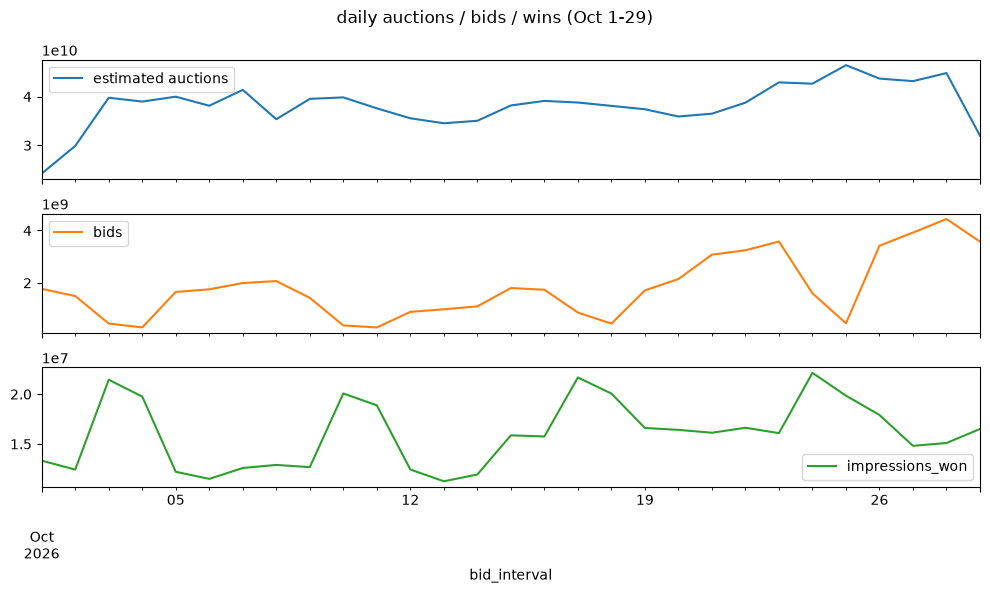

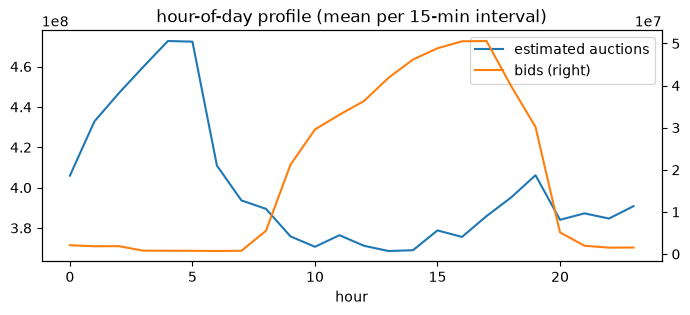

whole-period: bid rate 4.75%, win rate 0.88%, CPM $9.95


In [404]:
# Traffic profile: seasonality + rates over time
tp = pd.read_csv(TRAFFIC_DIR / "Traffic profile 20261102.csv", parse_dates=["bid_interval"])
daily = tp.set_index("bid_interval").resample("D")[["estimated auctions", "bids", "impressions_won"]].sum()
daily.plot(subplots=True, figsize=(10, 6), title="daily auctions / bids / wins (Oct 1-29)")
plt.tight_layout(); plt.show()

tp["hour"] = tp["bid_interval"].dt.hour
tp.groupby("hour")[["estimated auctions", "bids"]].mean().plot(
    secondary_y="bids", figsize=(8, 3), title="hour-of-day profile (mean per 15-min interval)"
)
plt.show()

agg_bid_rate = tp["bids"].sum() / tp["estimated auctions"].sum()
agg_win_rate = tp["impressions_won"].sum() / tp["bids"].sum()
print(f"whole-period: bid rate {agg_bid_rate:.2%}, win rate {agg_win_rate:.2%}, "
      f"CPM ${1000 * tp['estimated_cost'].sum() / tp['impressions_won'].sum():.2f}")

p50:    140 s  (2.3 min)
p80:    847 s  (14.1 min)
p90:   1451 s  (24.2 min)
p95:   2293 s  (38.2 min)
p99:   4689 s  (78.2 min)


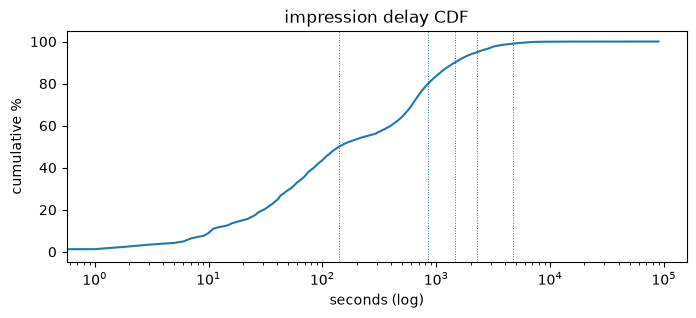

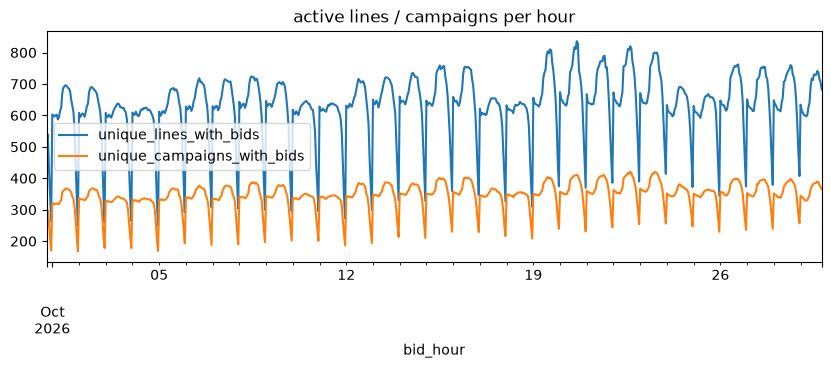

         auctions_rps
avg_rps      443868.5
p25_rps      387236.0
p50_rps      439907.0
p75_rps      496623.0
p90_rps      564293.0
p99_rps      692974.0
max_rps     1922200.0
           bids_ps
avg_bps   20981.97
p25_bps     811.00
p50_bps    4334.00
p75_bps   29916.00
p90_bps   66241.00
p99_bps  141938.00
max_bps  372996.00


In [405]:
# Impression-delay CDF + active entities + RPS summary
delay = pd.read_csv(TRAFFIC_DIR / "Impression delay histogram.csv")
ax = delay.plot(x="impress_delay_seconds_bucket", y="cumulative_pct", logx=True,
                legend=False, title="impression delay CDF", figsize=(8, 3))
ax.set_xlabel("seconds (log)"); ax.set_ylabel("cumulative %")
for pct in (50, 80, 90, 95, 99):
    sec = delay.loc[delay["cumulative_pct"] >= pct, "impress_delay_seconds_bucket"].iloc[0]
    ax.axvline(sec, ls=":", lw=0.7)
    print(f"p{pct}: {sec:>6.0f} s  ({sec/60:.1f} min)")
plt.show()

act_h = pd.read_csv(TRAFFIC_DIR / "Active Campaigns and Active Lines per Hour.csv", parse_dates=["bid_hour"])
act_h.set_index("bid_hour")[["unique_lines_with_bids", "unique_campaigns_with_bids"]].plot(
    figsize=(10, 3), title="active lines / campaigns per hour")
plt.show()

print(pd.read_csv(TRAFFIC_DIR / "Auction Requests per second.csv").T.rename(columns={0: "auctions_rps"}))
print(pd.read_csv(TRAFFIC_DIR / "Bids per second.csv").T.rename(columns={0: "bids_ps"}))

**Findings (6):** _to fill_

## 7. Economics / bid shading

**Feeds: the max-bid-cap discussion and the win-rate / bid-landscape
research direction.**

- `bid_price_micros_usd` vs `win_price_micros_usd` distributions and
  ratio (shading depth); `bid_shading_info.*`; `exchange_bid_price`.
- Win price vs the losing candidates' `bidding.bid_price_micros` —
  the per-auction bid landscape.
- CPM sanity check against the traffic profile's ~USD 10.

`prices_cpm` — the three prices attached to each won impression, in
USD CPM (raw stream fields are micro-USD per impression; CPM = micros
/ 1,000):

- **bid_cpm_usd** — what the DSP bid for the impression.
- **win_cpm_usd** — what was actually paid (after bid shading).
- **exchange_bid_cpm_usd** — the price submitted to the exchange.
- **win_over_bid** — paid / bid, unitless: 1.0 = paid the full bid; the
  gap below 1.0 is the bid-shading saving.

The histogram shows the win_over_bid distribution; the shading
reduction is also shown in USD CPM.

bid_cpm_usd  win_cpm_usd  exchange_bid_cpm_usd  win_over_bid
count          0.0          0.0                   0.0           0.0
mean           NaN          NaN                   NaN           NaN
std            NaN          NaN                   NaN           NaN
min            NaN          NaN                   NaN           NaN
25%            NaN          NaN                   NaN           NaN
50%            NaN          NaN                   NaN           NaN
75%            NaN          NaN                   NaN           NaN
max            NaN          NaN                   NaN           NaN

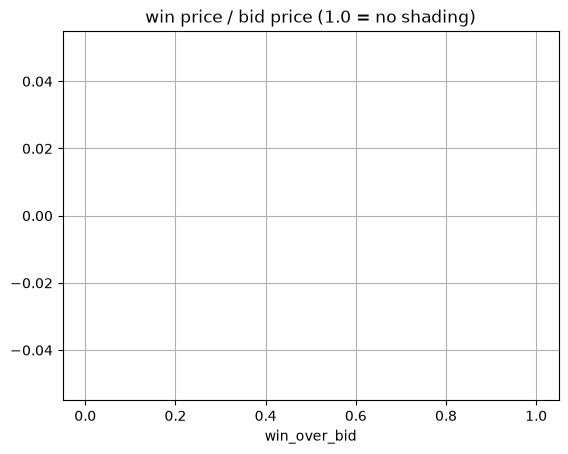

bid-shading reduction, USD CPM: {'count': 706.0, 'mean': 1.5, 'std': 1.35, 'min': 0.0, '25%': 0.9, '50%': 1.6, '75%': 1.85, 'max': 18.21}


In [406]:
prices_cpm = pd.DataFrame({
    "bid_cpm_usd": pd.to_numeric(events["impression.bid_price_micros_usd"], errors="coerce") / 1_000,
    "win_cpm_usd": pd.to_numeric(events["impression.win_price_micros_usd"], errors="coerce") / 1_000,
    "exchange_bid_cpm_usd": pd.to_numeric(events["impression.exchange_bid_price_micros_usd"], errors="coerce") / 1_000,
}, index=events["auction_key"])
prices_cpm["win_over_bid"] = prices_cpm["win_cpm_usd"] / prices_cpm["bid_cpm_usd"]
display(prices_cpm.describe().round(2))

prices_cpm["win_over_bid"].hist(bins=40)
plt.title("win price / bid price (1.0 = no shading)")
plt.xlabel("win_over_bid")
plt.show()

shading_cpm_usd = pd.to_numeric(
    events["impression.bid_shading_info.bid_shade_reduction_micros"], errors="coerce"
) / 1_000
print("bid-shading reduction, USD CPM:", shading_cpm_usd.describe().round(2).to_dict())

In [407]:
scored = candidates.merge(winners, on="auction_key")
scored["role"] = (scored["line_item_id"] == scored["won_line_item_id"]).map(
    {True: "winner", False: "loser"}
)
# micro-USD per impression -> USD CPM, the unit bids are quoted in
scored["bid_cpm_usd"] = scored["bid_micros"] / 1_000
bid_by_role = scored.groupby("role")["bid_cpm_usd"].describe().round(2)
bid_by_role

count  mean   std  min   25%   50%  75%   max
role                                                  
loser   3636.0  6.66  0.80  5.0  6.00  6.41  7.1  13.0
winner   933.0  8.54  3.69  5.0  6.52  7.41  9.0  50.0

**Findings (7):** _to fill_